In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import itertools
import time
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import make_scorer, precision_recall_curve
from sklearn.preprocessing import FunctionTransformer, StandardScaler

from heart import config as cfg
from heart.data import load_raw, make_splits
from heart.preprocessing import build_preprocessor
from heart.models import build_model, get_specs
from heart.config import FIGURES

In [2]:
# Define a function to save figures
def save_fig(name: str) -> None:
    """Save the current figure into reports/figures/."""
    FIGURES.mkdir(parents=True, exist_ok=True)
    plt.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")

In [3]:
# Load data
df = load_raw()
X_train, X_test, y_train, y_test = make_splits(df)

Calculating Metrics: 100%|██████████| 123/123 [00:00<00:00, 3442.93it/s]

Data validation PASSED: 36/36 checks successful


In [4]:
# Check the splits work
print("rows:", len(X_train), len(X_test))
print("disease rate:", y_train.mean().round(3), y_test.mean().round(3))
print("zero-chol share:", (X_train["Cholesterol"] == 0).mean().round(3),
      (X_test["Cholesterol"] == 0).mean().round(3))

# See if the features split evenly
Xt = build_preprocessor().fit_transform(X_train)
print(Xt.shape, int(Xt["chol_missing"].sum()))
Xt.describe()

rows: 734 184
disease rate: 0.553 0.554
zero-chol share: 0.187 0.19
(734, 19) 137


,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,Sex_M,ExerciseAngina_Y,FastingBS_1,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up,chol_missing
count,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000,734.000000
mean,-0.065348,0.093099,0.049555,-0.021316,0.011750,0.780654,0.405995,0.232970,0.539510,0.188011,0.217984,0.054496,0.196185,0.613079,0.190736,0.070845,0.501362,0.427793,0.186649
std,0.724924,0.832185,0.885860,0.716954,0.622283,0.414086,0.491418,0.423012,0.498776,0.390987,0.413158,0.227148,0.397381,0.487377,0.393149,0.256740,0.500339,0.495096,0.389895
min,-1.848126,-2.283505,-2.794141,-1.856291,-4.092509,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,-0.538272,-0.514587,-0.445753,-0.505720,-0.544627,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000
75%,0.461728,0.485413,0.554247,0.494280,0.455373,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000
max,1.852728,1.799157,2.340342,1.713941,1.343625,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [5]:
# Metrics and cross validation
SCORING = {
    "accuracy": "accuracy",
    "recall": "recall",
    "precision": "precision",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "brier": "neg_brier_score",
}

cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=5, random_state=cfg.SEED)

fold_scores = {}  

In [6]:
# Function to run the cross validation and return scores
def run_cv(name, model):
    # Cross-validate on the training set and store the per-fold scores.
    raw = cross_validate(model, X_train, y_train, cv=cv, scoring=SCORING,
                         return_train_score=True, n_jobs=-1)
    scores = pd.DataFrame({k: v for k, v in raw.items()
                           if k.startswith(("test_", "train_"))})
    scores[["test_brier", "train_brier"]] *= -1  # back to "lower is better"
    fold_scores[name] = scores

In [7]:
# Function to summarize metrics per model
def summary():
    # One row per model: validation mean ± std, plus the train/validation ROC AUC gap.
    metrics = ["recall", "precision", "f1", "roc_auc", "pr_auc", "brier", "accuracy"]
    rows = {}
    for name, s in fold_scores.items():
        row = {m: f"{s['test_' + m].mean():.3f} ± {s['test_' + m].std():.3f}"
               for m in metrics}
        row["auc_gap"] = round(s["train_roc_auc"].mean() - s["test_roc_auc"].mean(), 3)
        rows[name] = row
    return pd.DataFrame(rows).T

In [8]:
# Run for the 3 baseline models, dummy majority, dummy startified and logistic regression
baselines = {
    "dummy_majority": DummyClassifier(strategy="most_frequent"),
    "dummy_stratified": DummyClassifier(strategy="stratified", random_state=cfg.SEED),
    "logreg": make_pipeline(build_preprocessor(), LogisticRegression(max_iter=1000)),
}

for name, model in baselines.items():
    run_cv(name, model)

summary()

,recall,precision,f1,roc_auc,pr_auc,brier,accuracy,auc_gap
dummy_majority,1.000 ± 0.000,0.553 ± 0.005,0.712 ± 0.004,0.500 ± 0.000,0.553 ± 0.005,0.447 ± 0.005,0.553 ± 0.005,0.0
dummy_stratified,0.607 ± 0.060,0.548 ± 0.054,0.576 ± 0.057,0.493 ± 0.067,0.553 ± 0.032,0.495 ± 0.067,0.505 ± 0.067,0.006
logreg,0.902 ± 0.050,0.868 ± 0.037,0.884 ± 0.030,0.928 ± 0.026,0.935 ± 0.024,0.102 ± 0.021,0.869 ± 0.033,0.01


In [9]:
# Start over and rank all models to find the best ones based on roc_auc
fold_scores = {}  
for name in get_specs():
    start = time.time()
    run_cv(name, build_model(name))
    print(f"{name:18s} {time.time() - start:5.1f}s")

# Sort by mean validation ROC AUC
order = sorted(fold_scores, key=lambda n: -fold_scores[n]["test_roc_auc"].mean())
summary().loc[order]

dummy_majority       1.9s
dummy_stratified     1.8s
logreg               2.3s
knn                  2.3s
decision_tree        1.3s
random_forest        9.0s
xgboost              2.2s
lightgbm             3.0s
catboost             5.2s


,recall,precision,f1,roc_auc,pr_auc,brier,accuracy,auc_gap
logreg,0.902 ± 0.050,0.868 ± 0.037,0.884 ± 0.030,0.928 ± 0.026,0.935 ± 0.024,0.102 ± 0.021,0.869 ± 0.033,0.01
random_forest,0.913 ± 0.048,0.861 ± 0.041,0.885 ± 0.029,0.927 ± 0.027,0.925 ± 0.036,0.101 ± 0.019,0.869 ± 0.033,0.073
catboost,0.903 ± 0.048,0.870 ± 0.039,0.885 ± 0.029,0.925 ± 0.027,0.919 ± 0.036,0.099 ± 0.022,0.871 ± 0.032,0.07
xgboost,0.898 ± 0.051,0.874 ± 0.042,0.885 ± 0.033,0.923 ± 0.029,0.921 ± 0.037,0.101 ± 0.024,0.871 ± 0.037,0.069
knn,0.905 ± 0.046,0.863 ± 0.036,0.883 ± 0.029,0.923 ± 0.030,0.915 ± 0.037,0.103 ± 0.021,0.867 ± 0.032,0.023
lightgbm,0.892 ± 0.055,0.865 ± 0.043,0.877 ± 0.034,0.918 ± 0.030,0.916 ± 0.037,0.109 ± 0.028,0.862 ± 0.038,0.082
decision_tree,0.886 ± 0.062,0.832 ± 0.036,0.857 ± 0.037,0.884 ± 0.039,0.876 ± 0.045,0.127 ± 0.029,0.837 ± 0.040,0.051
dummy_majority,1.000 ± 0.000,0.553 ± 0.005,0.712 ± 0.004,0.500 ± 0.000,0.553 ± 0.005,0.447 ± 0.005,0.553 ± 0.005,0.0
dummy_stratified,0.607 ± 0.060,0.548 ± 0.054,0.576 ± 0.057,0.493 ± 0.067,0.553 ± 0.032,0.495 ± 0.067,0.505 ± 0.067,0.006


In [10]:
# Settings for the following plots
BLUE, ORANGE, GRID, INK = "#2a78d6", "#eb6834", "#d9d8d3", "#52514e"
REFERENCE = "logreg"
MODELS = [m for m in fold_scores if not m.startswith("dummy")]
N_SPLITS = cv.cvargs["n_splits"]
 
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "figure.dpi": 110,
})


# Fold scores: boxplots
Each box is the 50 validation scores of one model. Boxes that overlap heavily are tied.
The reference (logreg) is orange it can be seen who actually clears it.

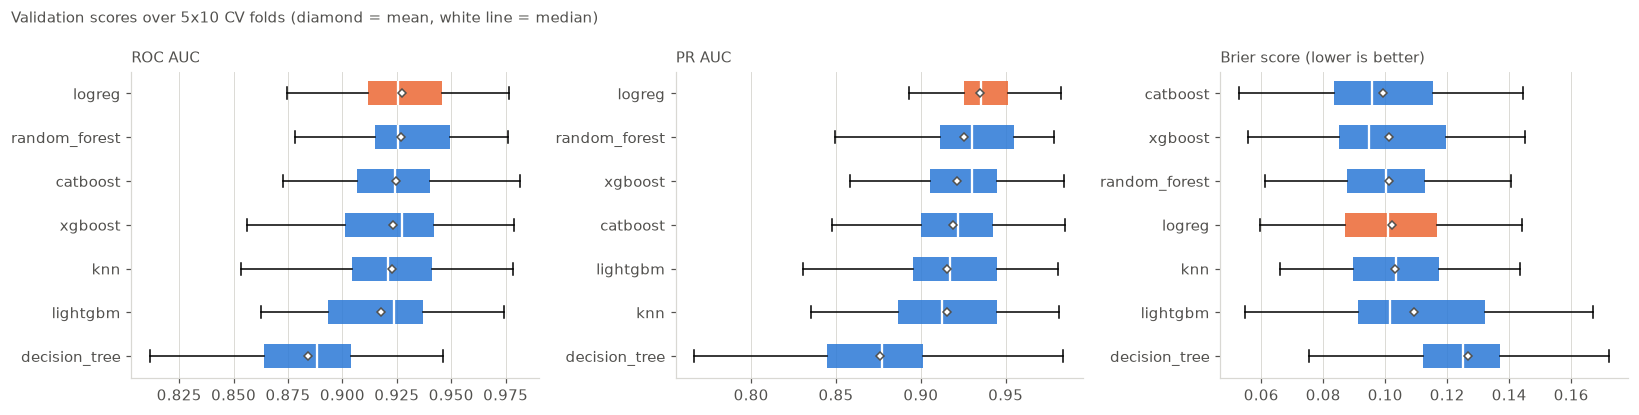

In [11]:
def boxplot_metric(metric, ax, lower_is_better=False, title=None):
    key = f"test_{metric}"
    order = sorted(MODELS, key=lambda n: fold_scores[n][key].mean(), reverse=not lower_is_better)
    bp = ax.boxplot([fold_scores[n][key] for n in order], vert=False, widths=0.55,
                    showmeans=True, patch_artist=True, showfliers=False,
                    medianprops={"color": "white", "linewidth": 1.5},
                    meanprops={"marker": "D", "markerfacecolor": "white",
                               "markeredgecolor": INK, "markersize": 4})
    for patch, name in zip(bp["boxes"], order):
        patch.set(facecolor=ORANGE if name == REFERENCE else BLUE, alpha=0.85, linewidth=0)
    ax.set_yticks(range(1, len(order) + 1), order)
    ax.invert_yaxis()  # best on top
    ax.set_title(title or metric + (" (lower is better)" if lower_is_better else ""),
                 loc="left", fontsize=10, color=INK)
    ax.grid(axis="y", visible=False)
 
 
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=False)
boxplot_metric("roc_auc", axes[0], title="ROC AUC")
boxplot_metric("pr_auc", axes[1], title="PR AUC")
boxplot_metric("brier", axes[2], lower_is_better=True, title="Brier score (lower is better)")
fig.suptitle("Validation scores over 5x10 CV folds (diamond = mean, white line = median)",
             x=0.01, ha="left", fontsize=10, color=INK)
fig.tight_layout()
save_fig("10_validation_scores")
plt.show()


# Findings

Across the 50 validation folds evaluated via repeated 10-fold cross-validation, logistic regression emerges as the top-performing classifier, achieving the highest mean ROC AUC (~0.926) and a distinctly superior PR AUC (~0.934). The advantage of logreg is particularly pronounced in PR AUC, where its interquartile range remains elevated above the competing models and its lower quartile rivals the medians of the tree ensembles, demonstrating robust precision across positive-class retrieval thresholds.

Ensemble methods such as random_forest, catboost, and xgboost form a tightly clustered secondary tier in discriminative ability, recording mean ROC AUC values between ~0.922 and ~0.925 and mean PR AUC values between ~0.919 and ~0.925. In contrast, lightgbm exhibits slightly reduced discriminative performance (~0.917 ROC AUC, ~0.915 PR AUC), while the standalone decision_tree underperforms considerably across all metrics (~0.885 ROC AUC, ~0.876 PR AUC) alongside substantial fold-to-fold variance.

In probabilistic calibration measured via Brier score where lower values reflect better probability estimates, catboost achieves the lowest mean error (~0.099), followed closely by xgboost (~0.101), random_forest (~0.101), and logreg (~0.102). Although gradient-boosted ensembles yield marginally tighter probability calibration, the calibration gap between catboost and logreg remains within 0.003. lightgbm (~0.117) and decision_tree (~0.126) display markedly worse calibration error distributions and higher dispersion.

# Overfitting: train vs validation AUC

The gap shows how much a model memorises. A big gap with an equal validation score means the model is just more flexible, not better.


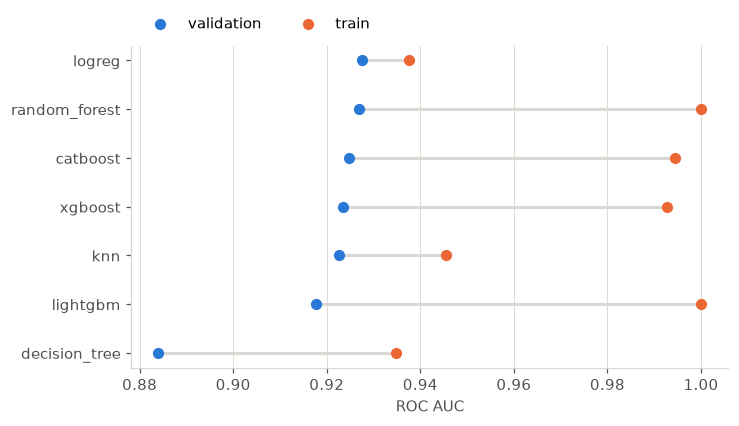

In [13]:
gap = pd.DataFrame({
    "train": {m: fold_scores[m]["train_roc_auc"].mean() for m in MODELS},
    "validation": {m: fold_scores[m]["test_roc_auc"].mean() for m in MODELS},
}).sort_values("validation")
 
fig, ax = plt.subplots(figsize=(7, 3.8))
y = np.arange(len(gap))
ax.hlines(y, gap["validation"], gap["train"], color=GRID, linewidth=2, zorder=1)
ax.scatter(gap["validation"], y, color=BLUE, s=40, zorder=2, label="validation")
ax.scatter(gap["train"], y, color=ORANGE, s=40, zorder=2, label="train")
ax.set_yticks(y, gap.index)
ax.set_xlabel("ROC AUC")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
save_fig("11_overfitting")
plt.show()


# Findings

Comparing training and validation ROC AUC reveals clear differences in model capacity and variance. The tree-based architectures (random_forest, lightgbm, catboost, and xgboost) demonstrate pronounced generalization gaps (0.07–0.08), achieving near-perfect training AUC scores (0.99–1.00). In random_forest and gradient boosters, this represents nominal memorization mitigated by ensembling, maintaining validation scores around 0.923–0.926. In lightgbm, however, this excessive capacity actively penalizes generalization, resulting in a noticeably lower validation AUC of 0.918. Conversely, logistic regression demonstrates superior stability with a negligible gap of only 0.010 between train (0.937) and validation (0.927), demonstrating that a constrained linear hypothesis space avoids overfitting noise while achieving the best generalizability across all models.

# Paired comparison against the reference

All models were scored on the same 50 folds, so the right comparison is the per-fold difference, not two overlapping std bars. Folds share training data, so a plain t-test is too confident. The Nadeau-Bengio correction inflates the variance by (1/k + n_test/n_train). Verdict: "tied" unless the 95% interval excludes zero. Positive difference = better than the reference, for every metric (Brier is flipped).

In [14]:
def paired_stats(candidate, reference, lower_is_better=False):
    d = np.asarray(candidate, float) - np.asarray(reference, float)
    if lower_is_better:
        d = -d
    k = len(d)
    se = np.sqrt(d.var(ddof=1) * (1 / k + 1 / (N_SPLITS - 1)))
    if se == 0:
        return {"diff": d.mean(), "ci_low": d.mean(), "ci_high": d.mean(), "p": 1.0,
                "win_rate": (d > 0).mean(), "verdict": "tied"}
    t = d.mean() / se
    lo, hi = stats.t.interval(0.95, df=k - 1, loc=d.mean(), scale=se)
    verdict = "better" if lo > 0 else "worse" if hi < 0 else "tied"
    return {"diff": d.mean(), "ci_low": lo, "ci_high": hi,
            "p": 2 * stats.t.sf(abs(t), df=k - 1), "win_rate": (d > 0).mean(), "verdict": verdict}
 
 
def paired_table(reference=REFERENCE):
    rows = []
    for metric, lower in [("roc_auc", False), ("pr_auc", False), ("brier", True)]:
        for name in MODELS:
            if name == reference:
                continue
            s = paired_stats(fold_scores[name][f"test_{metric}"],
                             fold_scores[reference][f"test_{metric}"], lower)
            rows.append({"metric": metric, "model": name, **s})
    return pd.DataFrame(rows).set_index(["metric", "model"])
 
 
paired = paired_table()
paired.round(4)

diff  ci_low  ci_high       p  win_rate verdict
metric  model                                                           
roc_auc knn           -0.0048 -0.0175   0.0078  0.4487      0.30    tied
        decision_tree -0.0435 -0.0698  -0.0171  0.0017      0.06   worse
        random_forest -0.0006 -0.0102   0.0091  0.9063      0.50    tied
        xgboost       -0.0040 -0.0150   0.0069  0.4628      0.42    tied
        lightgbm      -0.0098 -0.0224   0.0028  0.1242      0.28    tied
        catboost      -0.0027 -0.0124   0.0070  0.5798      0.36    tied
pr_auc  knn           -0.0193 -0.0386   0.0000  0.0505      0.30    tied
        decision_tree -0.0590 -0.0890  -0.0290  0.0002      0.06   worse
        random_forest -0.0096 -0.0260   0.0069  0.2471      0.38    tied
        xgboost       -0.0134 -0.0320   0.0052  0.1534      0.30    tied
        lightgbm      -0.0192 -0.0398   0.0013  0.0657      0.32    tied
        catboost      -0.0155 -0.0314   0.0004  0.0552      0.20    tied
brier   knn           -0.0010 -0.0079   0.0058  0.7665      0.46    tied
        decision_tree -0.0247 -0.0430  -0.0063  0.0095      0.18   worse
        random_forest  0.0008 -0.0060   0.0075  0.8222      0.52    tied
        xgboost        0.0010 -0.0079   0.0099  0.8265      0.54    tied
        lightgbm      -0.0073 -0.0194   0.0048  0.2311      0.30    tied
        catboost       0.0029 -0.0047   0.0105  0.4509      0.58    tied

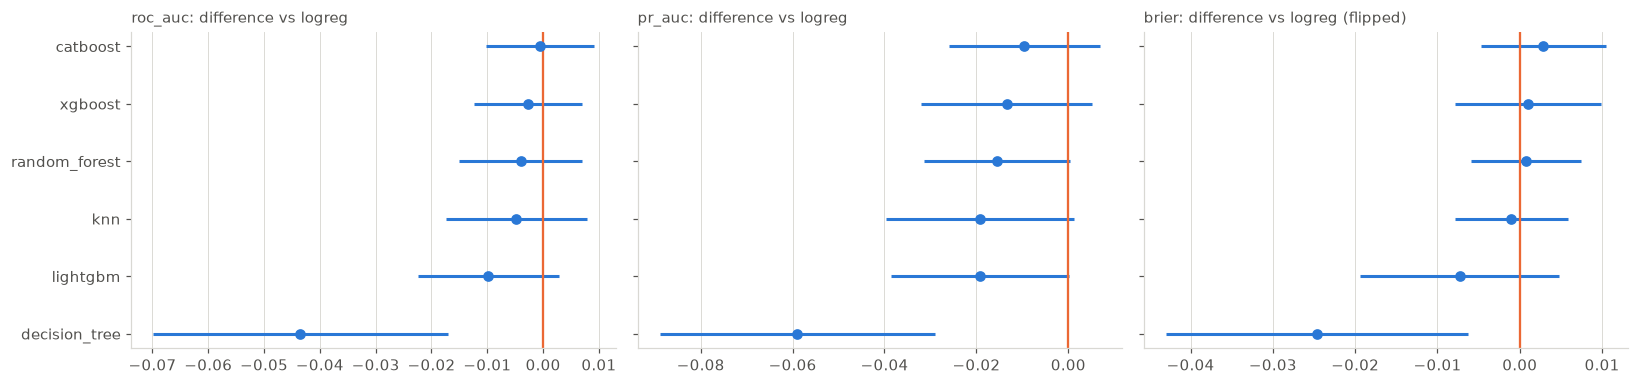

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, metric in zip(axes, ["roc_auc", "pr_auc", "brier"]):
    t = paired.loc[metric].sort_values("diff")
    y = np.arange(len(t))
    ax.hlines(y, t["ci_low"], t["ci_high"], color=BLUE, linewidth=2)
    ax.scatter(t["diff"], y, color=BLUE, s=36, zorder=3)
    ax.axvline(0, color=ORANGE, linewidth=1.5)
    ax.set_yticks(y, t.index)
    ax.set_title(f"{metric}: difference vs {REFERENCE}"
                 + (" (flipped)" if metric == "brier" else ""), loc="left", fontsize=10, color=INK)
    ax.grid(axis="y", visible=False)
fig.tight_layout()
save_fig("12_paired_comparisons")
plt.show()


# Findings

To isolate model performance differences from fold-level variance, paired difference tests were conducted across all cross-validation folds using logistic regression as the baseline reference (x = 0). The paired analysis confirms that no machine learning architecture achieves a statistically significant improvement over logistic regression in either discrimination (ROC AUC, PR AUC) or probabilistic calibration (Brier score). While catboost and xgboost show marginal point-estimate improvements in Brier score (0.001–0.003), their 95% confidence intervals overlap zero, indicating the calibration difference is statistically indistinguishable from noise. Furthermore, in PR AUC, all alternative models display negative mean differences, with logistic regression maintaining superior precision across recall thresholds. Single decision trees perform significantly worse across all three axes (p < 0.05). Applying the principle of parsimony, logistic regression is confirmed as the champion model, offering equivalent or superior empirical performance alongside complete interpretability, lower operational overhead, and negligible inference latency. 